In [1]:

## Clone your forked repository to Colab ##

## Specify your GitHub username:
user_name <- "a-gidding"

## Specify the repository:
repo_name <- "STAT-7110-Quality-Control"

## Set the web address to your forked repository:
repo_address <- paste0(
  "https://github.com/",
  user_name,
  "/",
  repo_name,
  ".git"
)

## Check to see if repo is already cloned to Colab, and if not, clone repo:
if (!dir.exists(repo_name)) {
  system(paste("git clone", repo_address))
} else {
  print("Repository already cloned to Colab.")
}
## Set working drive to today's lecture (update the folder name to match your repo):

setwd("/content/STAT-7110-Quality-Control/Assignments/HW4")

### go ahead and run the libraries necessary for this assignment ###

library(tidyverse)
library(readxl)
library(qcc)
library(dplyr)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Package 'qcc' version 2.7

Type 'citation("qcc")' for citing this R package in publications.



## Homework 4 - Analysis Using Hotelling's $T^2$ and Multiple Stream Process Control Charts
### Dr. Austin Brown
### Kennesaw State University

**DUE: November 20, 2026 via D2L**

## Instructions:

You are the director of The Owl's Nest, a psychological services program at a local university that employs a team of four Clinical Psychology PhD students to offer counseling services to the campus community at a steep discount. When a new client comes in, they commit to biweekly sessions for at least one semester. At the start of each session, the client completes a brief survey assessing depressive symptoms using Likert-scale items (e.g., "How much do you agree with this statement, on a scale from 1 (strongly disagree) to 5 (strongly agree)?"). The total score ranges from 20 to 100, with higher scores indicating more severe depressive symptoms.

If a counselor's client scores begin trending upward over time, that may indicate a need for you, as the director, to step in -- whether by providing additional training and supervision, or by referring a client to a higher level of care. Because all four counselors work in the same training program, share office space and supervision, and often see clients during the same high-stress points in the academic calendar (midterms, finals), you suspect their clients' scores may be correlated with one another from week to week, rather than behaving as four completely independent processes.

To monitor this, you perform an initial Phase I analysis, jointly monitoring the scores of all four counselors across the 16-week fall semester, taking a sample of 5 clients per week for each counselor. After confirming statistical control, you'll monitor the subsequent 16-week spring semester (Phase II) to determine whether anything has changed.

## Key Specifications

| Quantity | Value |
|---|---|
| Quality characteristic | Total depressive-symptom survey score (20-100 scale) |
| Number of counselors (streams) | 4 |
| Clients sampled per counselor per week (n) | 5 |
| Phase I weeks (m) | 16 (fall semester) |
| Phase II weeks (m) | 16 (spring semester) |
| Control Chart for Each Stream design value | $L = 3.46$ |

## Define & Measure

### Q1: Briefly describe the purpose of this analysis

The purpose of this analysis is to monitor the depressive symptoms of the four on campus counselors over the course of the Fall semester.

### Q2: Identify the quality characteristic being monitored, and classify its measurement scale. Why might it be reasonable to suspect that the four counselors' weekly scores are correlated with one another, rather than fully independent?

The quality characteristic being monitored is the depressive symptom survey score which is measured on a scale of 20-100. This appears to be an interval variable as the higher the number gets, the worse the ranking is in terms of the client's mental state.

It is reasonable to suspect that the scores could be correlated because there are frequently periods in which all students are experiencing the same stressors. Some of those periods may include midterms and finals, which can drive depressive symptoms and in turn raise the clients' scores.

### Q3: Given your answer to Q2, briefly explain why it might be reasonable to treat this scenario as a **multivariate process** (suggesting a Hotelling's $T^2$ chart) rather than a **multiple stream process** (suggesting the Control Chart for Each Stream technique). Under what different assumption would the opposite framing make more sense?

The multivariate process could be better to measure initially since there is the probability of correlation. This will allow us to see the patterns of all of the counselors in the same space rather than trying to review each counselors scores individually and compare them.

If we assumed that there was independence amongst our counselors' weekly scores,we would instead use the multiple stream process. This would be more appropriate at that point because we still want to do a general comparison, but this time it would be without the degrees of correlation, which would still allow for comparison while no longer requiring the charts to be in the same space.

## Analyze

### Q4: Read the Phase I data (`Counselling_PhaseI.xlsx`) into R as a list, one data frame per counselor (HINT: use `qcc::mqcc`, and make sure to remove the `Week` column from each data frame, possibly using `lapply`). Construct a Phase I Hotelling's $T^2$ chart. Do we have evidence of statistical control? Why or why not?

It appears that we do have evidence of statistical control. None of the points fell outside of the upper control limits, and we made sure to get the compounded false alarm rate so as we proceed, we can prepare to do any further analysis with that taken into consideration if necessary.

In [4]:
## Q4 Code ##

sn <- excel_sheets("Counselling_PhaseI.xlsx")

counselors <-lapply(sn,FUN=function(x){

  counsel <- read_xlsx("Counselling_PhaseI.xlsx",sheet=x) %>%
    dplyr::select(-`Week`)

  return(counsel)

})

names(counselors) <- paste("Counselor",1:4,sep="")

counselors["Counselor1"] |> glimpse()

List of 1
 $ Counselor1: tibble [16 × 5] (S3: tbl_df/tbl/data.frame)
  ..$ Client1: num [1:16] 40 52.4 43.7 64.2 40.5 ...
  ..$ Client2: num [1:16] 46.5 51.3 43 44.7 43.9 ...
  ..$ Client3: num [1:16] 38.3 45.6 50.6 50.5 54.4 ...
  ..$ Client4: num [1:16] 57.8 29.1 49.5 45.2 32.8 ...
  ..$ Client5: num [1:16] 47.6 50 39.5 39 49.8 ...


[1] 0.01075634

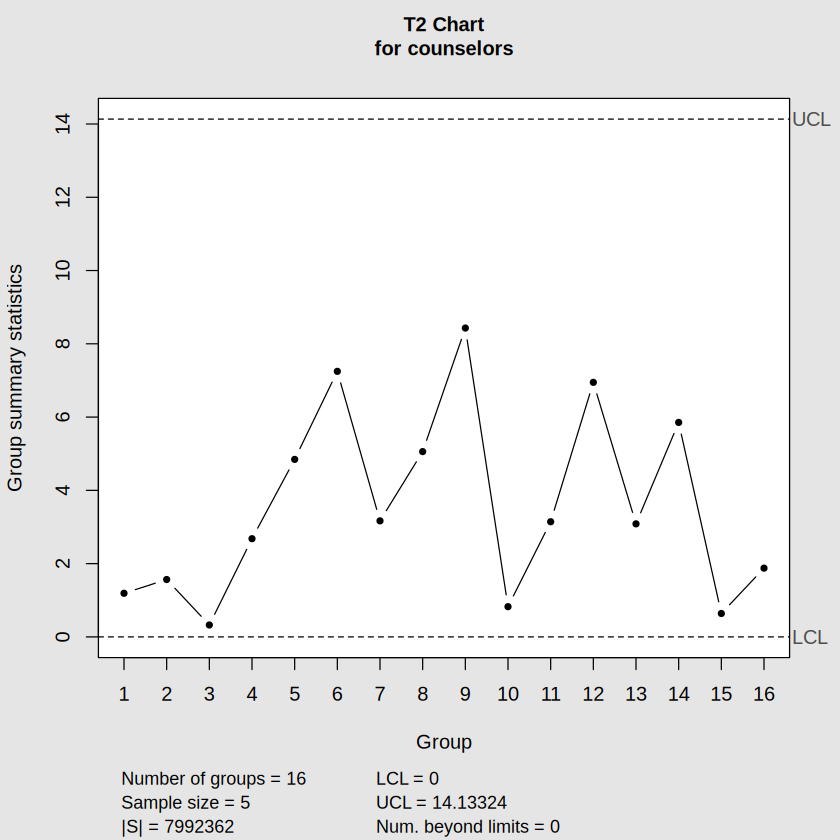

In [11]:
## building the t chart separately ##
t2_counsel <- mqcc(counselors,type='T2')

## need to consider the false alarm rate correction ##
1 - (0.9973)^4

### Q5: Report the sample mean vector and sample variance-covariance matrix from Q4.

In [14]:
## Q5 Code ##

t2_counsel$center

t2_counsel$cov

Counselor1 Counselor2 Counselor3 Counselor4 
  45.34275   46.00288   45.28650   45.45975

,Counselor1,Counselor2,Counselor3,Counselor4
Counselor1,64.94685,25.20394,18.73784,28.36822
Counselor2,25.20394,63.96758,30.76070,26.36930
Counselor3,18.73784,30.76070,67.29034,14.95226
Counselor4,28.36822,26.36930,14.95226,60.67095


### Q6: Read the Phase II data (`Counselling_PhaseII.xlsx`) into R the same way. Using the mean vector and covariance matrix from Q5, construct a Phase II Hotelling's $T^2$ chart. Do we still have evidence of statistical control? If not, generate individual univariate Shewhart $\bar{X}$ and $s$ charts (using the appropriate mean and standard deviation from Phase I) to determine which counselor(s) may have out-of-control scores.

After running the phase two data, it is clear that the process is not in control. What is odd is that it appears that all of the Counselors fall outside of the preset control limits. With that being said, Counselor 3 has a mean significantly above that of the other three counselors, with their mean score sitting almost 20 points above that of the other counselors.

In [17]:
## Q6 Code ##

sn2 <- excel_sheets("Counselling_PhaseII.xlsx")

counsel2 <- lapply(sn2,FUN=function(x){

  d <- read_xlsx("Counselling_PhaseII.xlsx",sheet=x) %>%
    dplyr::select(-`Week`)

  return(d)

})

names(counsel2) <- paste("Counselor",1:4,sep="")


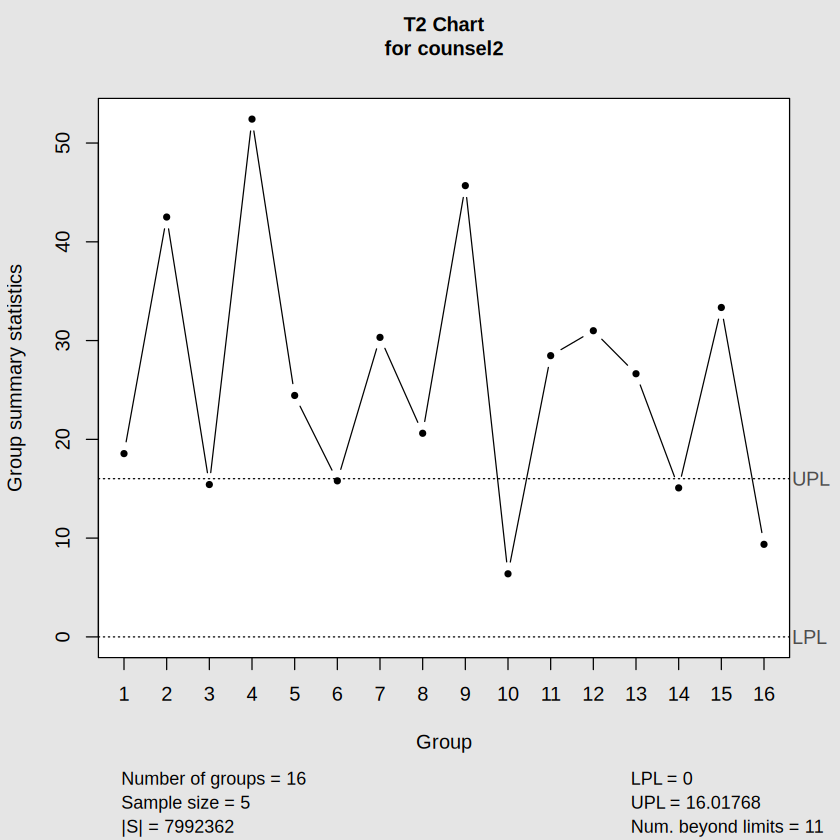

In [19]:
counsel_p2 <- mqcc(counsel2,type="T2",
           center=t2_counsel$center,
           cov=t2_counsel$cov,
           limits=F,pred.limits=T,
           plot=T)

In [22]:
lapply(counsel2,FUN=function(x){

  return(mean(rowMeans(x)))

})

c4 <- 0.0108

$Counselor1
[1] 46.16112

$Counselor2
[1] 44.43162

$Counselor3
[1] 59.6185

$Counselor4
[1] 44.552

In [33]:
coun1_xbar <- t2_counsel$center[1]
coun2_xbar <- t2_counsel$center[2]
coun3_xbar <- t2_counsel$center[3]
coun4_xbar <- t2_counsel$center[3]

coun1_sd <- sqrt(t2_counsel$cov[1,1])/c4
coun2_sd <- sqrt(t2_counsel$cov[2,2])/c4
coun3_sd <- sqrt(t2_counsel$cov[3,3])/c4
coun4_sd <- sqrt(t2_counsel$cov[4,4])/c4

In [32]:
coun1_ucl <- coun1_xbar + 3*coun1_sd
coun1_lcl <- coun1_xbar - 3*coun1_sd

coun2_ucl <- coun2_xbar + 3*coun2_sd
coun2_lcl <- coun2_xbar - 3*coun2_sd

coun3_ucl <- coun3_xbar + 3*coun3_sd
coun3_lcl <- coun3_xbar - 3*coun3_sd

coun4_ucl <- coun4_xbar + 3*coun4_sd
coun4_lcl <- coun4_xbar - 3*coun4_sd

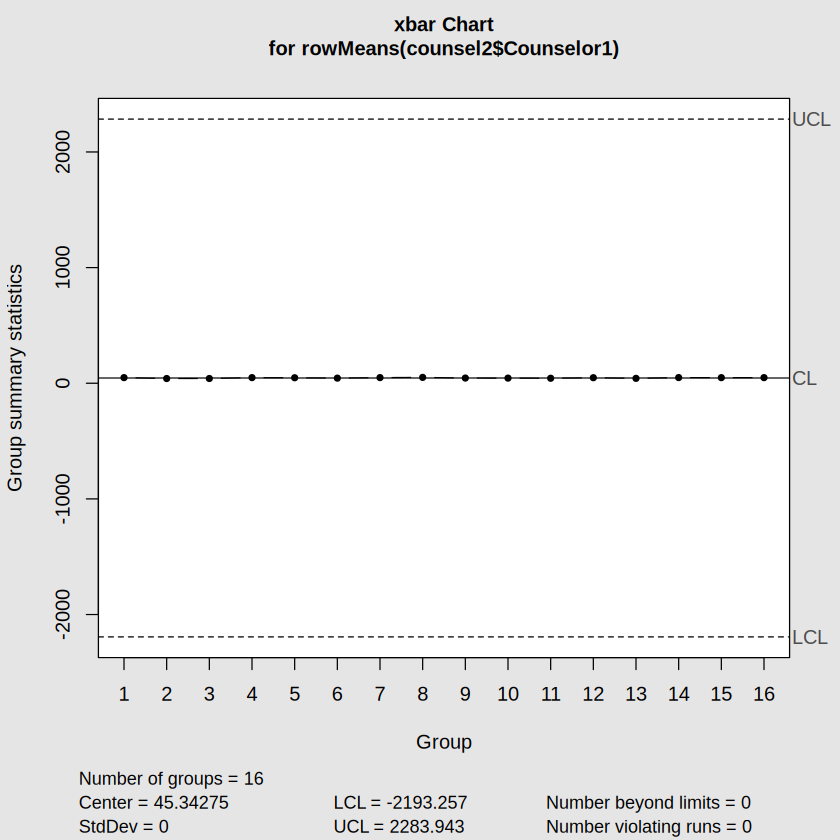

In [29]:
xbar1 <- qcc(rowMeans(counsel2$Counselor1),
             type="xbar",
             center=coun1_xbar,
             sigma=coun1_sd,
             sizes=5,
             limits=c(coun1_lcl,coun1_ucl))

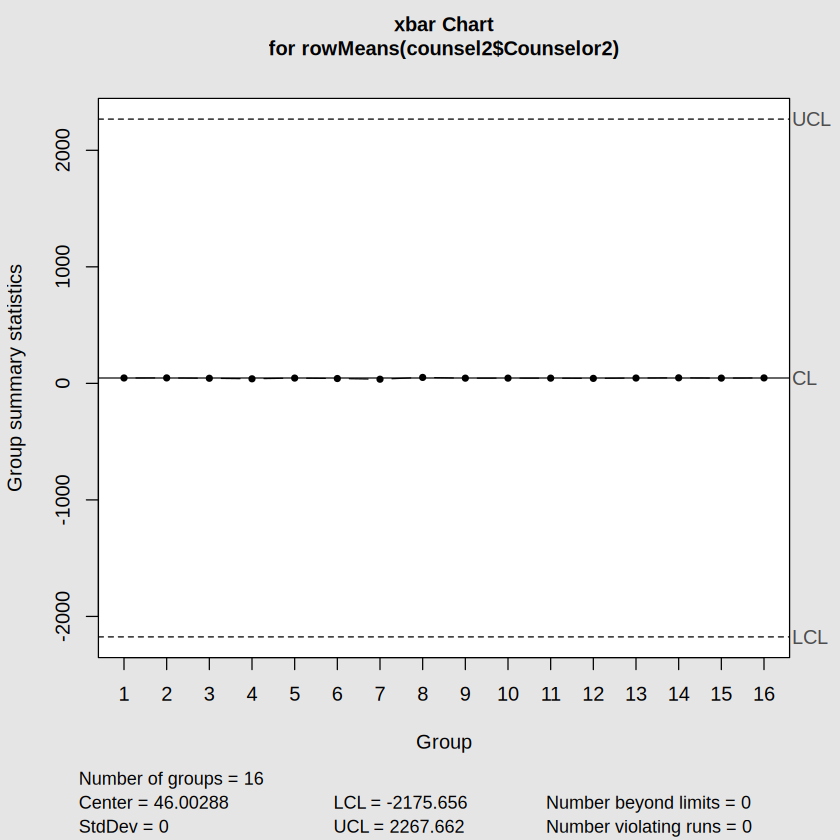

In [28]:
xbar2 <- qcc(rowMeans(counsel2$Counselor2),
             type="xbar",
             center=coun2_xbar,
             sigma=coun2_sd,
             sizes=5,
             limits=c(coun2_lcl,coun2_ucl))

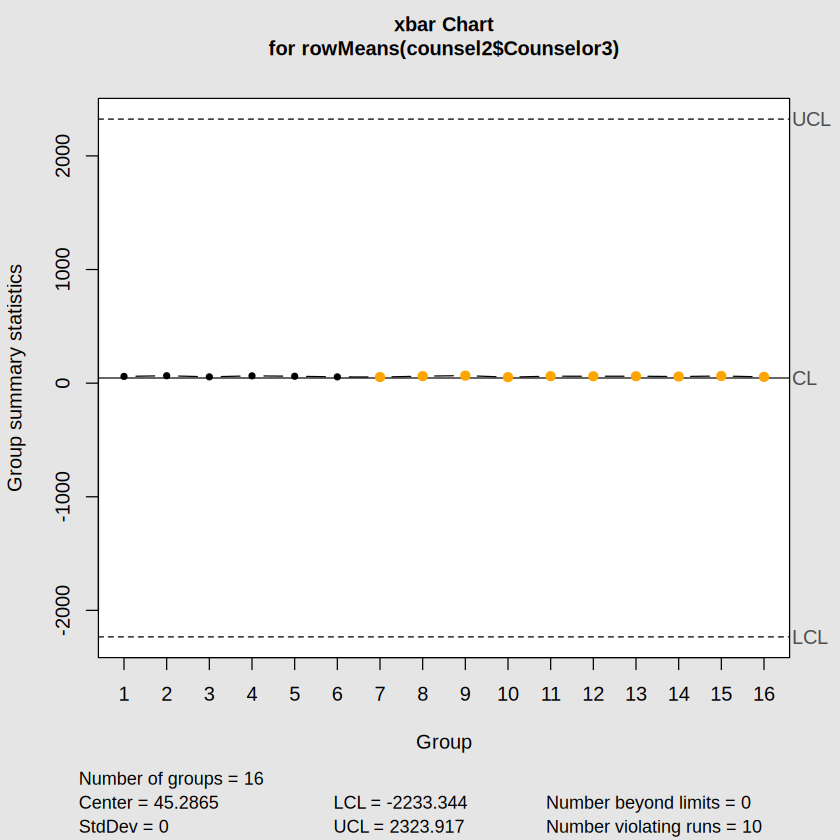

In [30]:
xbar3 <- qcc(rowMeans(counsel2$Counselor3),
             type="xbar",
             center=coun3_xbar,
             sigma=coun3_sd,
             sizes=10,
             limits=c(coun3_lcl,coun3_ucl))

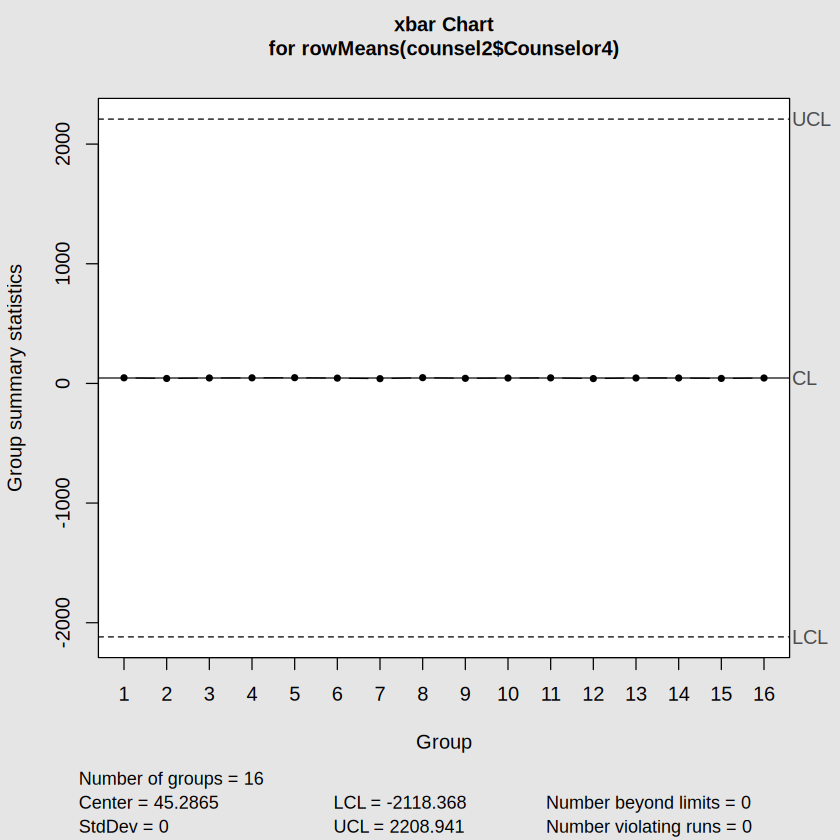

In [31]:
xbar4 <- qcc(rowMeans(counsel2$Counselor4),
             type="xbar",
             center=coun4_xbar,
             sigma=coun4_sd,
             sizes=5,
             limits=c(coun4_lcl,coun4_ucl))

### Q7: What is the benefit of using a multivariate control chart over several separate univariate control charts? What is one limitation?

The benefit of the multivariate chart is that we can see all of the counselors compared iwthin the same chart, which is

## Improve

### Q8: Based on your findings in Q6, briefly describe what intervention(s) you, as the director, might reasonably take regarding the counselor(s) flagged as out of control.

## Control

### Q9: It is reasonable to assume that this same monitoring situation could also be conceptualized as a **multiple stream process (MSP)** -- that is, treating the four counselors as independent, parallel processes rather than a single correlated multivariate one. Perform the same Phase I analysis as before, but using the Control Chart for Each Stream MSP technique ($L = 3.46$). Do we have evidence of statistical control?

In [ ]:
## Q9 Code ##

### Q10: Perform Phase II analysis using the Control Chart for Each Stream MSP technique. Do we still have evidence of statistical control? If not, which stream(s) (i.e., counselors) may be causing the out-of-control point(s)?

In [ ]:
## Q10 Code ##

### Q11: What is a difference between a multivariate process and a multiple stream process? Given what you found in Q4-Q10, which framing do you think is the more defensible choice for this specific scenario, and why?

### Q12: Provide an overview of your results that you, as the director, could bring to the university's Vice President of Student Affairs. What is the current status of The Owl's Nest program, and what actions (if any) have you taken or would you recommend?